In [1]:
import json
import os
from pathlib import Path

import geopandas as gpd
import networkx as nx
import numpy as np

DATA_DIR = Path(os.environ.get("DATA_DIR"))
print(f"Data dir: {DATA_DIR}")

Data dir: /Users/Artsem_Nikitsenka/experimental-python/data


,group_index,value,center,area,reachfactor,total_pop,geometry
0,0,200.0,"[30.95437, 52.426232]",4506081.64,0.0465,48721.0,"POLYGON ((30.94303 52.43087, 30.94074 52.42397..."
1,0,300.0,"[30.95437, 52.426232]",11540020.78,0.0529,106705.0,"POLYGON ((30.92365 52.42424, 30.92363 52.42389..."
2,1,200.0,"[30.95437, 52.426232]",4506081.64,0.0465,48721.0,"POLYGON ((30.94303 52.43087, 30.94074 52.42397..."
3,1,300.0,"[30.95437, 52.426232]",11540020.78,0.0529,106705.0,"POLYGON ((30.92365 52.42424, 30.92363 52.42389..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

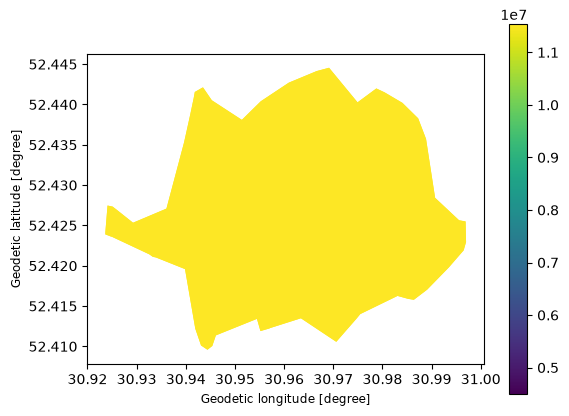

In [2]:
isochrones_driving_car_gdf = gpd.read_file(
    DATA_DIR
    / "in/geospatial/BY/Gomel/isochrones/driving-car-[[30.954133,52.426097],[30.954133,52.426097]].geojson"
)
display(isochrones_driving_car_gdf)
isochrones_driving_car_gdf.plot("area", legend=True)

In [3]:
def show_adjacency_matrix():
    with open(
        DATA_DIR
        / "in/geospatial/BY/Gomel/matrix/driving-car-[[30.954133,52.426097],[30.954133,52.426097]].json",
        "r",
        encoding="utf-8",
    ) as file:
        data = json.load(file)

    matrix_data = np.array(data["distances"], dtype=float)
    graph = nx.from_numpy_array(matrix_data, create_using=nx.DiGraph)
    adj_matrix = nx.adjacency_matrix(graph, weight="weight")
    print(adj_matrix.toarray())
    print(f"nodes: {list(graph.nodes())}")
    if graph.number_of_nodes() > 1 and nx.has_path(graph, 0, 1):
        path = nx.shortest_path(graph, 0, 1, weight="weight")
        print(path)
    else:
        print("No path between 0 and 1 for the selected metric.")


show_adjacency_matrix()

[[0. 0.]
 [0. 0.]]
nodes: [0, 1]
No path between 0 and 1 for the selected metric.


In [4]:
def create_graph(gdf: gpd.GeoDataFrame):
    graph = nx.Graph()

    # Add all polygons as nodes
    for idx, row in gdf.iterrows():
        graph.add_node(idx, geometry=row.geometry)

    gdf_metric = gdf.to_crs(epsg=3857)
    gdf_buffered = gdf_metric.copy()
    gdf_buffered["geometry"] = gdf_metric.geometry.buffer(0.1)

    # Change predicate to "intersects" since they now overlap
    adjacencies = gpd.sjoin(gdf_buffered, gdf_buffered, predicate="intersects")

    # Add edges between the matching index pairs
    for left_idx, right_idx in zip(adjacencies.index, adjacencies["index_right"]):
        if left_idx != right_idx:  # Avoid self-loops
            graph.add_edge(left_idx, right_idx)
        else:
            print("self-loop")

    return graph


graph = create_graph(isochrones_driving_car_gdf)
print(graph.nodes(data=True))
print(graph.edges())

self-loop
self-loop
self-loop
self-loop
[(0, {'geometry': <POLYGON ((30.943 52.431, 30.941 52.424, 30.941 52.424, 30.942 52.421, 30.94...>}), (1, {'geometry': <POLYGON ((30.924 52.424, 30.924 52.424, 30.925 52.424, 30.925 52.424, 30.93...>}), (2, {'geometry': <POLYGON ((30.943 52.431, 30.941 52.424, 30.941 52.424, 30.942 52.421, 30.94...>}), (3, {'geometry': <POLYGON ((30.924 52.424, 30.924 52.424, 30.925 52.424, 30.925 52.424, 30.93...>})]
[(0, 1), (0, 3), (0, 2), (1, 3), (1, 2), (2, 3)]
